# Regression Basics/Review

*"The advantage of bad memory is that one enjoys many times the same good things for the first time."*
<br>
-Nietzsche
<br><br>
This lesson has three goals:
 
- Review/introduce [Regression Fundamentals](#Regression-Fundamentals)
- Review/introduce the concept of ["Identifying Variation"](#Identifying-Variation)
- Discuss the [Frisch-Waugh-Lovell (FWL)](#Frisch-Waugh-Lovell-(FWL)) theorem
    
Data scientists use and interpret regressions on a regular basis, but many have little understanding of what's going on "under the hood." Without a strong grasp of the mechanics underlying regressions, it is difficult to think critically about how to optimally construct or modify these analyses. This notebook serves as a brief discussion of how regression coefficients are constructed, and will provide fundamental knowledge necessary for future discussions of causal inference methods.
</br>

<a id='Regression-Fundamentals'></a>
## Regression Fundamentals

If you're reading this, you should be familiar with the standard regression equation:
</br>
$y_{i} = \hat{\beta_{0}} + \hat{\beta_{1}}x_{i1} + \cdots + \hat{\beta_{k}}x_{ik} + \epsilon_{i}$
</br>
>**Note**: the hats represent estimated values.

Each $\hat{\beta_{i}}$ represents the associated change in $\hat{y}$ for a one unit change in $x_{i}$, conditional on other independent variables.

### Key Questions

Ask yourself:
- How is $\hat{\beta_{i}}$ estimated/calculated?
- Should we expect it to change if we include more (or fewer) variables in our regression?
- If it does change, why?
- Does the magnitude of $\hat{\beta_{i}}$ say anything about the "importance" of its corresponding $x_{i}$?

## How is $\hat{\beta_{i}}$ Estimated?

Economists usually describe how regression coefficients are estimated by using linear algebra. To be specific, given $n$ observations of $k$ independent variables (the $x_{i}$s) and a dependent variable ($y$), we can use the following notation:
$$
    \begin{bmatrix}
        y_{0} \\
        y_{1} \\
        \vdots      \\
        y_{n}
    \end{bmatrix}
    =
    \begin{bmatrix} 
        1       & x_{12} & \cdots & x_{1k} \\ 
        1       & x_{22} & \cdots & x_{2k} \\ 
        \vdots  & \vdots & \ddots & \vdots \\
        1       & x_{n2} & \cdots & x_{nk} 
    \end{bmatrix}
    \times
    \begin{bmatrix}
        \hat{\beta_{0}} \\
        \hat{\beta_{1}} \\
        \vdots          \\
        \hat{\beta_{k}}
    \end{bmatrix}
    +
    \begin{bmatrix}
        \epsilon_{0} \\
        \epsilon_{1} \\
        \vdots       \\
        \epsilon_{n}
    \end{bmatrix}
$$
Or, more succinctly: 
\begin{equation}
    Y = X\hat{B} + E
\end{equation}
where $E$ is the vector of error terms.
</br></br></br>
We care about this because economists typically use calculus to solve regression equations (as opposed to, say, gradient decent). Given these equations, one can find the error term for any single observation, $\epsilon_{i}$, by evaluating the difference between observed and predicted outcomes. In matrix notation, this can be written:

\begin{equation} 
    E = Y - X\hat{B}
\end{equation}
</br></br>
As a reminder, regressions work by minimizing the sum of squared errors; that is, they minimize $E^{'}E$. Using the equation above, determining our coefficients, $B$, becomes a fairly straightforward process. 
1. Compute $E^{'}E$. 
2. Take the derivative with respect to $\hat{B}$ and set it equal to zero.
3. Solve for $\hat{B}$. 

This process is shown explicitly below:
</br></br>
__Step 1:__
\begin{align*}
    E^{'}E &= (Y - X\hat{B})^{'} (Y - X \hat{B}) \\
           &= Y^{'}Y - 2Y^{'}X\hat{B} + \hat{B^{'}}X^{'}X\hat{B}
\end{align*}
__Step 2:__
\begin{align*}
    \frac{\partial (E^{'}E)}{\partial B} &= -2(X^{'}Y - X^{'}X\hat{B}) = 0
\end{align*}
__Step 3:__
\begin{align*}
    \hat{B} &= (X^{'}X)^{-1}X^{'}Y
\end{align*}
</br>

To make this point as clearly as possible, we can review the intuition underlying this process with the illustration below:
<br>

<table style="margin-left: auto; margin-right: auto;">
  <tr>
    <td align="center">
      <img src="./images/sst_ssr_sse_decomp_visual.png"
           width="500"
           height="500"
           alt="SST, SSR, SSE decomposition" />
    </td>
  </tr>
</table>
<br>

This graphic shows how residuals are calculated, with the residual for a single observation illustrated by the orange line segment. Regressions determine the line of best fit by minimizing the Sum of Squares Residual Errors (SSE) across all observations, which is equivalent to minimizing $E^{'}E$ in our math above. We just showed mathematically that the slope of the regression, $\hat{\beta}$, is determined by minimizing SSE.
<br>

Note that SSE is calculated relative to Sum of Squares Total (SST), which is the squared prediction error we would incur with the simplest model possible &mdash; fitting to the mean of the data. Calculating SST is similar to calculating the variance of $Y$: 
- $SST = \Sigma_{i=1}^{n}(y_{i} - \overline{y})^{2}$
- $Var(Y) = \frac{\Sigma_{i=1}^{n}(y_{i} - \overline{y})^{2}}{n-1}$

Because of this I like to think of SST as measuring the "total variation" in Y, though this is admittedly imprecise language. Still, under this framework some portion of the variation in $Y$ can be "explained" by our regression. This value is provided by the Sum of Squares Regression (SSR). Meanwhile, SSE represents the portion of SST that is "unexplained" by our regression. This notion of "explained" and "unexplained" variation will become more important as we continue through the lesson.

#### <a id='Identifying-Variation'></a>
## Identifying Variation

So far we've done some math to show _how_ regressions work, but we haven't really provided any intuition for _why_ it's useful to know these equations. To provide this motivation, consider a simple bivariate regression; that is, condsider $y_{i} = \hat{\beta_{0}} + \hat{\beta_{1}}x_{i} + \epsilon_{i}$. In this case, you could solve for a single regression coefficient, $\hat{\beta_{1}}$, by following the same process we used to solve for $\hat{B}$ above. Among other reasons, this is a nice starting point because our process does not require linear algebra when there is only one independent ($x$) variable. If you do the math, you'll find that:

\begin{equation*}
    \hat{\beta_{1}} = \frac{\Sigma_{i=1}^{n}(x_{i} - \overline{x})(y_{i} - \overline{y})}{\Sigma_{i=1}^{n}(x_{i} - \overline{x})^{2}}
\end{equation*}

</br>
This is a nice equation because it is easily simplified, and provides the foundation for the rest of our discussion in this notebook. To get this started, let's first recall the equations for sample covariance and sample variance:
</br></br>
\begin{align*}
    Cov(x,y) & = \frac{\Sigma_{i=1}^{n}(x_{i} - \overline{x})(y_{i} - \overline{y})}{n - 1} \\
    Var(x) &= \frac{\Sigma_{i=1}^{n}(x_{i} - \overline{x})^{2}}{n - 1}
\end{align*}
</br>
With these in hand, we can see that the equation for $\hat{\beta_{1}}$ becomes:
</br></br>
\begin{equation*}
    \hat{\beta_{1}} = \frac{Cov(x,y)}{Var(x)}
\end{equation*}
</br>

This is our first introduction to the concept of __identifying variation__. By this, I mean that in order for $\hat{\beta_{1}}$ to be __identified__, there must be __variation__ in x. If there is no variation in x, then the denominator in our equation is 0, and $\hat{\beta_{1}}$ is undefined. 
</br>

This has important implications for regression analysis. For example, one might note that a reduction in the magnitude of the variance in x, holding all else constant, will generally lead to an increase in the magnitude of $\hat{\beta_{1}}$. Many practitioners incorrectly assume that large regression coefficients indicate a strong covariance between x and y (i.e., a large numerator). We should be careful about this assumption; it could just as easily be the case that we lack identifying variation. Thus, a large regression coefficient may not indicate that its corresponding variable is more "important" than others.
</br>

Still, you might be wondering what the big deal is. Sure, we've shown that an interesting equation holds true for _bivariate_ regressions, but, in its current form, it does not hold true for more complex regressions. To that end, the rest of our work in this notebook will center around generalizing the equation for $\hat{\beta_{i}}$ above. It turns out that with only a few extra steps, _any_ regression coefficient can be framed in terms of a similar fraction &mdash; even if the regression contains many independent variables. In fact, we'll see that _identifying variation is actually just the variation in $x$ that is "unexplained" by all other covariates in our regression_. In the case of a bivariate regression there are no other covariates, so this "unexplained" variation is equivalent to all the variation in $x$. Understanding this process provides a vastly greater appreciation for how regression analysis works, the information it provides, and its limitations.
</br>

<a id='Frisch-Waugh-Lovell-(FWL)'></a>
## Frisch-Waugh-Lovell (FWL)

The previous section introduced the concept of identifying variation through the lens of a bivariate regression. Specifically, when there is only one independent variable in the regression, we showed that:

\begin{equation*}
    \hat{\beta_{1}} = \frac{Cov(x,y)}{Var(x)}
\end{equation*}

It turns out that there is a remarkably simple (and elegant) theorem that extends this relationship to _any_ regression. Specifically, the __Frisch-Waugh-Lovell (FWL) theorem__ says the following:

***
Suppose that we are interested in estimating the coefficients in a multiple
regression with k independent variables. We can partition our independent variables into two non-empty sets: $X_{1}$
containing the $k^{'}$ independent variables on which our analysis is focused and $X_{2}$ containing $k^{''}$ = $k - k^{'}$
additional "controls":
</br>
\begin{equation}
    Y = X_{1}\hat{B_{1}} + X_{2}\hat{B_{2}} + E 
\end{equation}
</br>
As an alternative to our standard regression technique, we can perform the following:
1. Run $k^{'} + 1$ auxiliary regressions, one with each element of of $X_{1}$ as the dependent variable and one with $Y$. In each regression use $X_{2}$ as the set of independent variables. 
2. From each auxiliary regression, capture the error term. Denote these residuals as $X_{1}^{*}$ and $Y^{*}$.
3. Run the regression $Y^{*} = X_{1}^{*}\Gamma + \mu$
</br>
***

When performing this analysis, it turns out that the vector of coefficients $\Gamma$ are _identical_ to the vector of coefficients $\hat{B_{1}}$; $\Gamma = \hat{B_{1}}$. At first glance, this might seem a lot of extra work just to end up where we started. But the nifty result here &mdash; which might not be obvious in the statement above &mdash; is that _any_ regression coefficient can be framed in terms of the covariance/variance relationship we've been utilizing throughout this lesson. let's take some time to be specific about how the FWL theorm implies this, using the knowledge we've built throughout this notebook.
</br>

In particular, let's imagine we're interested in estimating _one_ specific coefficient; that is, let's imagine that $X_{1}$ contains only one variable. In this case, step 1 of the FWL procedure requires running only two auxiliary regressions: one with $X_{1}$ as the dependent variable and one with $Y$ as the dependent variable. In the first auxiliary regression, we are capturing the residuals of $X_{1}$ when regressing it on $X_{2}$. We call these saved residuals $X_{1}^{*}$, and they represent the portion of the "variation" in $X_{1}$ that is "unexplained" by $X_{2}$. Similarly, the second auxiliary regression captures in $Y^{*}$ the portion of the "variation" in $Y$ that is "unexplained" by $X_{2}$. 
</br>

We then regress these sets of residuals on each other &mdash; that is, we regress $Y^{*}$ on $X_{1}^{*}$. This is nice because both $Y^{*}$ and $X_{1}^{*}$ are $n \times 1$ vectors, which means this regression is dimensionally equivalent to the bivariate regression we introduced in our [Identifying Variation](#Identifying-Variation) section. For this reason, we can estimate our coefficient of interest using the same formula, but replacing $y$ and $x$ with $Y^{*}$ and $X_{1}^{*}$, respectively. Specifically, step 3 of the FWL theorem says that we can estimate $\Gamma$ with the following equation:

\begin{align*}
    \Gamma &= \frac{\Sigma_{i=1}^{n}(X_{1i}^{*} - \overline{X_{1}^{*}})(Y_{i}^{*} - \overline{Y^{*}})}{\Sigma_{i=1}^{n}(X_{1i}^{*} - \overline{X_{1}^{*}})^{2}} \\
    \Gamma &= \frac{Cov(X_{1}^{*},Y^{*})}{Var(X_{1}^{*})}
\end{align*}
</br>

Finally, taking the FWL theorem's result for granted, we can make use of the fact that $\Gamma = \hat{\beta_{1}}$:

\begin{equation*}
    \hat{\beta_{1}} = \frac{Cov(X_{1}^{*},Y^{*})}{Var(X_{1}^{*})}
\end{equation*}
</br>

The point of the exercise above was to show that _any_ regression coefficient can be framed in terms of our covariance/variance fraction. This has some useful implications for our work. First, it implies that you can _always_ show your audience a scatter plot and fitted line to illustrate a regression coefficient &mdash; even when you have many other independent variables. For technical audiences, this has the added benefit of showing them exactly what underlying data you are using to estimate you coefficient on $X_{1}$, and how its identifying variation is distributed.
</br>

On this note, let's spend some time reminding ourselves what identifying variation represents in this context. As before, we need our denominator to be something other than zero in order for $\hat{\beta_{1}}$ to be defined. But what does $Var(X_{1}^{*})$ represent, anyway? Remember, $X_{1}^{*}$ is the vector of residuals that results from a regression of $X_{1}$ on all other independent variables. Thus, $X_{1}^{*}$ can be thought of as representing the portion of the variation in $X_{1}$ that is "unexplained" by the other independent variables included in our regression. Likewise, $Y^{*}$ can be thought of as representing the portion of the variation in $Y$ that is "unexplained" by the other independent variables included in our regression
</br>

At a high level, you can think of this as exemplifying the issue of multicollinearity; the more collinear $X_{1}$ is with other independent variables, the less identifying variation will exist. In the absence of identifying variation, $\hat{\beta_{1}}$ may be greatly mis-estimated. Along a similar line of thinking, we can now explore, in a somewhat precise way, how adding additional variables to our regression might impact $\hat{\beta_{1}}$. If the additional variables are correlated with $X_{1}$, then our estimate of $\hat{\beta_{1}}$ will change. In practice, this will almost always be the case &mdash; even if the correlation is spurious. Whenever you run a regression, it's worth thinking about the source of your identifying variation. Being able to precisely describe your identifying variation gives you the ability to talk about your regression in comparison terms, which hones intuition and interpretation. We'll elaborate on this point in an upcoming example.
</br>

Next, we should note what this analysis implies about the limitations of regressions. Each coefficient can _only_ be estimated in the presence of identifying variation. If you lack this variation &mdash; perhaps because of the presence of multicollinearity &mdash; there might not be much you can do to estimate your coefficient of interest. This is, unfortunately, just the way it goes.
> A solution might be to search for an instrumental variable, but that's a discussion for another lesson.

<br>

Finally, given a regression in which we observe identifying variation for our variable of interest, we should ask ourselves what is _causing_ the identifying variation. This question is at the heart of all causal inference that utilizes regression models.
</br>

For example, if $Var(X_{1}^{*})$ would be reduced by the inclusion of additional control variables &mdash; perhaps because changes in these variables cause $X_{1}$ to change as well &mdash; then $\hat{\beta_{1}}$ does not identify the causal effect of $X_{1}$ on $Y$. Instead, $\hat{\beta_{1}}$ would identify an amalgamation of the effect of $X_{1}$ and the omitted control variables on $Y$. On the other hand, if $Var(X_{1}^{*})$ is _as good as random_ then $\hat{\beta_{1}}$ does identify the causal effect of $X_{1}$ on $Y$.
> We'll discuss what it means for $Var(X_{1}^{*})$ to be _as good as random_ in more detail in future lessons.

<br>

Our future lessons will revolve around establishing processes by which we can credibly claim $\hat{\beta_{1}}$ represents the causal effect of $X_{1}$ on $Y$. This will entail a substantial amount of technical detail, which can make it easy to lose sight of the connective tissue underlying the lessons. As we continue through our course, remember that while different methods should be applied to different circumstances, _every_ causal inference method exists to produce an estimate of $\hat{\beta_{1}}$ in which its identifying variation is _as good as random_. 
</br>

The remainder of this notebook will focus on providing an example of the FWL in practice, complete with illustrations.

### Illustrating the FWL Theorem

Let's dig into our FWL example. To kick things off, we'll be using the height_data.csv dataset, which you may remember from the take-home project during the interview process for NRG.
</br></br>
The dataset contains four variables: height, weight, age, and gender. For the purposes of this illustration, we'll build a linear regression to predict height using only weight and age. Of course, this is purely for the purpose of creating a simplified, illustatrive example; normally you will have far more than two independent variables. Still, the lessons learned here generalize to regressions with any number of independent variables.
</br></br>
As a reminder, our goal is to show that we can recreate _any_ single regression coefficient in our main regression by following the process outlined by the FWL theorem. For example, given the main regression below:
\begin{equation*}
    \text{height}_{i} = \hat{\beta_{0}} + \hat{\beta_{1}}\text{weight}_{i} + \hat{\beta_{2}}\text{age}_{i} + \epsilon_{i}
\end{equation*}
We could estimate $\hat{\beta_{1}}$ by using the following process:
1. Regress $y$ (height) on $x_{2}$ (age) and save the vector of residuals. We denote this vector of residuals $Y^{*}$.
2. Regress $x_{1}$ (weight) on $x_{2}$ (age) and save the vector of residuals. We denote this vector of residuals $X_{1}^{*}$.
3. Regress $Y^{*}$ on $X_{1}^{*}$.

By following this process we will demonstrate that $\hat{\beta_{1}} = \frac{Cov(\text{Y}^{*},\text{ } \text{X}_{1}^{*})}{Var(\text{X}_{1}^{*})}$. We'll also illustrate the concept of identifying variation; that is, we'll explicitly show what values $X_{1}^{*}$ takes.

In [13]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore") # code is old and may cause some warnings

In [9]:
df_height = pd.read_csv('data/height_data.csv')

Our first step is to run our main regression, so that we can see the coefficients in our "main" regression. After this, we'll follow the three step process outlined above, and show that the coefficient on weight is unchanged.

In [10]:
# x and y for our main regression
X_main = sm.add_constant(df_height[['weight', 'age']])
y_main = pd.DataFrame(df_height['height'])

# x_1, x_2, and y for our auxiliary regressions during the FWL process
y_aux = pd.DataFrame(df_height['height']) # Note that y_aux = y_main; this redundancy is just for expositional purposes
X1_aux = pd.DataFrame(df_height['weight'])
X2_aux = sm.add_constant(df_height['age'])

# main regression
main = sm.OLS(y_main, X_main)
main_reg = main.fit()
print(main_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                 height   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     2166.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          6.03e-259
Time:                        13:41:04   Log-Likelihood:                -1978.5
No. Observations:                 544   AIC:                             3963.
Df Residuals:                     541   BIC:                             3976.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         75.9633      1.042     72.890      0.0

</br>

The coefficient on weight is about 1.66. Most practitioners would tell you that the standard interpretation of this coefficient is that each one unit change in weight is associated with an approximately 1.66 unit change in height. This is _almost_ true, but not quite. We'll see why at the end of this example.
</br></br>
It turns out that FWL provides us with a more nuanced interpretation for $\hat{\beta_{1}}$. Moreover, it provides us with a better sense of the identifying variation at play than we might have using our standard regression alone. By following FWL, we can get the same regression coefficient for weight _and_ a ton of extra intuition. Given these claims, we'll dive into the three step FWL process outlined above.
</br></br>
Let's start by running our first auxiliary regression, which entails regressing height on all independent variables other than weight. Because our main regression has only two independent variables in it (weight and age), we can illustrate this auxiliary regression in a two dimensional plot. As a reminder, our goal is to save the residuals from this regression. These residuals are simply the vertical distance between each point and the regression's fitted line.
</br></br>

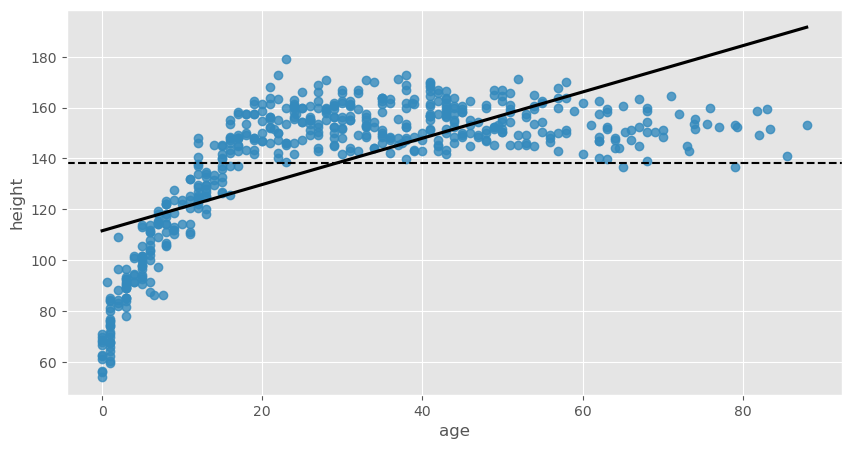

In [11]:
# first auxiliary regression
aux1 = sm.OLS(y_aux, X2_aux)
aux1_reg = aux1.fit()
y_star = pd.DataFrame(data=aux1_reg.resid, columns=['aux1_residuals']) #save residuals 
y_mean = y_aux.mean()

# plotting the regression
plt.style.use('ggplot')
plt.figure(figsize=(10,5))
sns.regplot(y=y_aux, x=X2_aux['age'], ci=None, color=sns.color_palette()[1], line_kws={"color": "black"}).axhline(y_mean[0], color="black", linestyle='--')

</br>
Great, we've created our first auxiliary regression. Don't worry about the odd shape of the data in this example; it's not important for our purposes. The main thing to note is that our regression "explains" some of the trend in height (SSR > 0), but imperfectly. While height does generally increase with age, there are clearly differences between what we observe in this data and what our regression predicts (SSE > 0). Loosely speaking, we can consider these differences, or residuals, to represent the portion of the variation in height that is "unexplained" by our regression.
</br></br>
Let's repeat this process with our second auxiliary regression, which entails regressing weight on all independent variables besides itself. As before, we can illustrate this regression in a two dimensional plot.
</br></br>

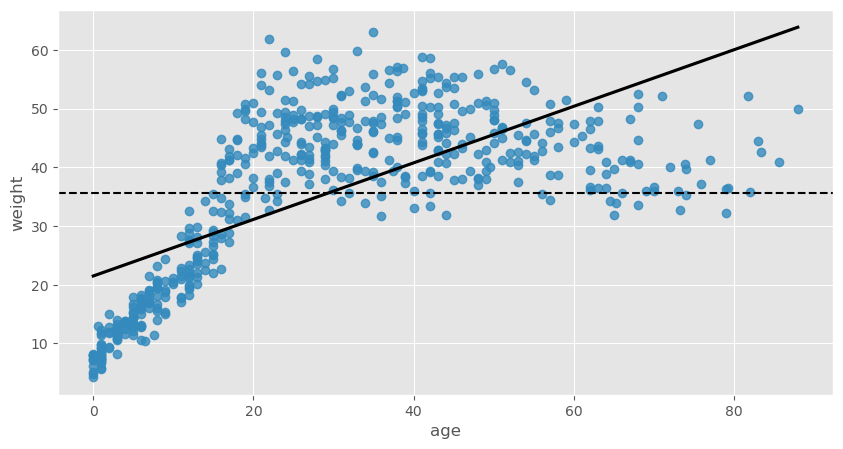

In [12]:
# second auxiliary regression 
aux2 = sm.OLS(X1_aux, X2_aux)
aux2_reg = aux2.fit()
x1_star = pd.DataFrame(data=aux2_reg.resid, columns=['aux2_residuals']) # save residuals
x_mean = X1_aux.mean()

# plotting the regression
plt.style.use('ggplot')
plt.figure(figsize=(10,5))
sns.regplot(y=X1_aux, x=X2_aux['age'], ci=None, color=sns.color_palette()[1], line_kws={"color": "black"}).axhline(x_mean[0], color='black', linestyle='--')

</br>
We now have our second auxiliary regression in hand, and the story is much the same as the first. Weight is predicted by age, but imperfectly. 
</br></br>
Importantly, this graph shows us that there is identifying variation present in our regression, which in turn means we are able to estimate the coefficient on weight in our main regression. Another way to express this is to say that age and weight are not perfectly collinear. If they were, we would not be able to disentangle the effects of age and weight on height.
</br></br>
At this point all we have left to do is regress the residuals from the first auxiliary regression on the residuals from the second. Here we will not only show the scatterplot, but print the regression output as well.
</br></br>

<Axes: xlabel='aux2_residuals', ylabel='aux1_residuals'>

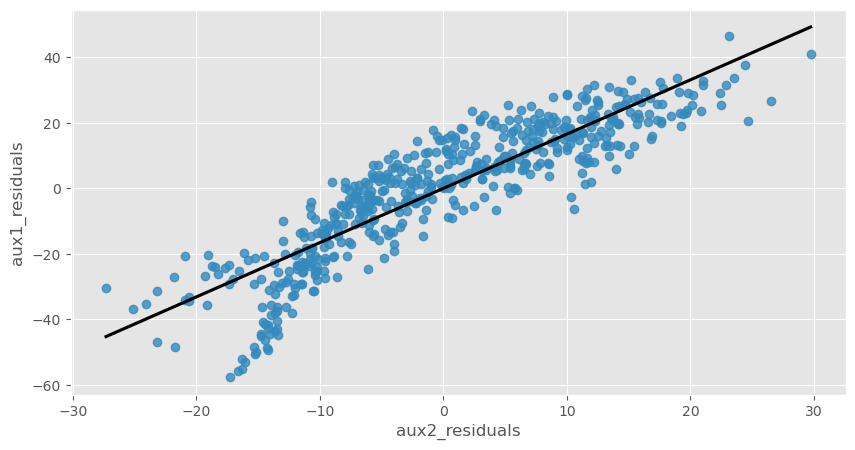

In [6]:
# final regression
fwl = sm.OLS(y_star, x1_star)
fwl_reg = fwl.fit()

# plotting the regression
plt.style.use('ggplot')
plt.figure(figsize=(10,5))
sns.regplot(y=y_star, x=x1_star, ci=None, color=sns.color_palette()[1], line_kws={"color": "black"})

In [7]:
# print the regression's output
print(fwl_reg.summary())

                                 OLS Regression Results                                
Dep. Variable:         aux1_residuals   R-squared (uncentered):                   0.792
Model:                            OLS   Adj. R-squared (uncentered):              0.791
Method:                 Least Squares   F-statistic:                              2062.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):                   5.01e-187
Time:                        13:40:31   Log-Likelihood:                         -1978.5
No. Observations:                 544   AIC:                                      3959.
Df Residuals:                     543   BIC:                                      3963.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------

<br/>

Two things should be immediately obvious here. First, note that the regression coefficient in this regressions is _identical_ to the coefficient on weight in our main regression. Second, note that we can illustrate this regression coefficient using a two dimensional graph. This would have been impossible in our main regression.
</br>

All of this is cool, but let's be sure not to lose sight of the forest for the trees. Remember, we motivated this example by showing that $\hat{\beta_{1}} = \frac{Cov(X_{1}^{*},Y^{*})}{Var(X_{1}^{*})}$. What we've done in this last graph is explicitly visualize this formula. That is to say, the slope of the regression line is equal to the covariance between the residuals in our two auxiliary regressions, divided by the variance of the residuals in our second auxiliary regression.
</br>

This is important for several reasons. First, this relationship helps us better understand how adding controls to our regression will affect our coefficient of interest. In particular, if you add controls that are correlated with $x_{1}$, you will reduce the amount of identifying variation present (that is, you will reduce $Var(X_{1}^{*})$).  Graphically, a reduction in $Var(X_{1}^{*})$ results in grouping points more closely together on our horizontal axis. In the most extreme case where $Var(X_{1}^{*}) = 0$, all our points would have the same position on our horizontal axis and the regression line will be vertical &mdash; that is, it will have an undefined slope. In general, as we reduce our identifying variation we increase the slope of our regression line, which corresponds to inflating $\hat{\beta_{1}}$. As data scientists, most of us are likely familiar with this phenomenon when multicollinearity is present -- still, we now understand explicitly why it occurs. This should drive home the point that a coefficient's magnitude does not necessarily imply anything about its feature importance.
</br>

Second, this discussion about identifying variation illuminates some limitations of regression analysis. You can _only_ estimate a coefficient when identifying variation is present. Remember, this identifying variation can be thought of as the portion of the variation in the variable of interest that is "unexplained" by all other independent variables. If your variable of interest is highly collinear with another independent variables, it is unlikely that you can separately identify their coefficients. 
</br>

Third, beyond simply measuring identifying variation, it is worth thinking about where it comes from. I mentioned earlier that being able to precisely describe your identifying variation gives you the ability to talk about your regression in comparison terms, so let's follow up on that point. In this example, we saw that $\hat{\beta_{1}}$ is derived by comparing the two sets of residuals from our auxiliary regressions. To be more specific, we are comparing two things: peoples' heights _relative to what you would expect, given their age_ and peoples' weights _relative to what your would expect, given their age_. Thus, our coefficient of interest is derived from a _conditional comparison_; it is only true when holding constant other variables in our regression. Following this logic, the correct interpretation for $\hat{\beta_{1}}$ is that a one unit change in weight is associated with a 1.66 unit change in height, _conditional on age_.
</br>

This might seem like a minor point, but it is important to keep it in mind when communicating with business stakeholders. Business strategies can be designed around the coefficients we estimate; it is important that we - and our partners - understand them clearly. 
</br>

To make this point a bit more obvious, let's consider an example. Suppose we are predicting height for two individuals. Further, let's assume that we know the difference between these individuals' weights is exactly one unit, but we have no knowledge of their age. Should we guess that there is also a 1.66 unit difference in their height? No! $\hat{\beta_{1}}$ was estimated conditional on age; we might get a different coefficient on weight if we ran a regression in which age was not included as a control variable because age and weight are correlated. Therefore, we should not apply $\hat{\beta_{1}}$ from our regression to analyses in which we don't observe our subjects' ages. Again, this might seem obvious to data scientists; we work with this stuff every day. But it is a level of nuance that is probably not obvious to your typical business partner.
</br>

Fourth, and finally, this will provide foundational knowledge as we move into deeper discussion of causal inference methods. Even though we have not yet formalized the requirements we will place on our data in order to have a regression estimate a causal parameter, it should be clear that adding control variables has the potential to help us in our quest. Multiple regression gives us the means to look at the relationship between $x$ and $y$, after eliminating the portion of the variation in both variables that is correlated with additional controls. In future lessons, we'll learn to think more carefully about exactly which controls we should include in our equation. By carefully considering which additional controls are included, we can get a better idea of where our identifying variation is coming from, and whether it can be used to estimate a causal relationship between $x$ and $y$.